In [ ]:

from google.colab import files

uploaded = files.upload()


Saving World_Energy_By_Country_And_Region_1965_to_2023.csv to World_Energy_By_Country_And_Region_1965_to_2023.csv


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "World_Energy_By_Country_And_Region_1965_to_2023.csv"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())


Dataset loaded successfully!
Dataset shape: (111, 60)

Column names:
['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']

First five rows:


,Country,1965,1966,1967,1968,1969,1970,1971,1972,1973,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Canada,5.00,5.32,5.57,5.92,6.28,6.73,6.94,7.47,8.11,...,14.43,14.47,14.34,14.54,14.72,14.64,13.76,13.92,14.30,13.95
2,Mexico,1.06,1.12,1.14,1.24,1.36,1.45,1.53,1.69,1.82,...,8.03,7.94,8.11,8.26,8.15,8.07,7.35,7.83,8.18,8.45
3,US,51.98,54.89,56.80,60.19,63.30,65.54,66.92,70.25,73.22,...,93.59,92.69,92.62,92.97,96.37,95.68,88.64,93.44,95.42,94.28
4,Total North America,58.04,61.33,63.51,67.36,70.95,73.72,75.39,79.41,83.16,...,116.04,115.10,115.07,115.76,119.25,118.40,109.75,115.20,117.90,116.68


In [ ]:

print("Country column available:", "Entity" in df.columns)
print("Year column available:", "Year" in df.columns)
print(
    "Energy column available:",
    "primary_energy_consumption" in df.columns
)

if "Entity" in df.columns:
    print(df["Entity"].dropna().unique()[:20])


Country column available: False
Year column available: False
Energy column available: False


In [ ]:

print(df.columns.tolist())
india = df[
    df["Country"].astype(str).str.strip().str.lower() == "india"
].copy()

print("India data selected successfully!")
display(india)



['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']
India data selected successfully!


,Country,1965,1966,1967,1968,1969,1970,1971,1972,1973,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
91,India,2.23,2.30,2.37,2.53,2.81,2.75,2.86,3.01,3.07,...,27.59,28.55,29.83,30.96,32.72,33.54,31.78,34.51,36.37,39.02


In [ ]:

# Remove empty rows and columns
india = india.dropna(how="all")
india = india.dropna(axis=1, how="all")

# Extract year columns
year_cols = [
    col for col in india.columns
    if str(col).isdigit()
]

# Convert wide format into year-wise rows
india_long = india.melt(
    id_vars=["Country"],
    value_vars=year_cols,
    var_name="Year",
    value_name="Energy_Consumption"
)

india_long["Year"] = pd.to_numeric(
    india_long["Year"], errors="coerce"
)
india_long["Energy_Consumption"] = pd.to_numeric(
    india_long["Energy_Consumption"], errors="coerce"
)

india_long = india_long.dropna(
    subset=["Year", "Energy_Consumption"]
).sort_values("Year")

print("Cleaned India data:")
display(india_long.head(10))

print("Total yearly records:", len(india_long))
print("Missing values:", india_long.isnull().sum().to_dict())


Cleaned India data:


,Country,Year,Energy_Consumption
0,India,1965,2.23
1,India,1966,2.30
2,India,1967,2.37
3,India,1968,2.53
4,India,1969,2.81
5,India,1970,2.75
6,India,1971,2.86
7,India,1972,3.01
8,India,1973,3.07
9,India,1974,3.25


Total yearly records: 59
Missing values: {'Country': 0, 'Year': 0, 'Energy_Consumption': 0}


In [ ]:

from sklearn.preprocessing import MinMaxScaler

# Prepare numerical data
values = india_long["Energy_Consumption"].values.reshape(-1, 1)

# Normalize values between 0 and 1
scaler = MinMaxScaler()
normalized_values = scaler.fit_transform(values)

india_long["Normalized_Consumption"] = normalized_values

print("Normalization completed!")
display(india_long.head(10))


Normalization completed!


,Country,Year,Energy_Consumption,Normalized_Consumption
0,India,1965,2.23,0.000000
1,India,1966,2.30,0.001903
2,India,1967,2.37,0.003805
3,India,1968,2.53,0.008154
4,India,1969,2.81,0.015765
5,India,1970,2.75,0.014134
6,India,1971,2.86,0.017124
7,India,1972,3.01,0.021201
8,India,1973,3.07,0.022832
9,India,1974,3.25,0.027725


In [ ]:

# Sort data chronologically
india_long = india_long.sort_values("Year").reset_index(drop=True)

# Get normalized values
data = india_long["Normalized_Consumption"].values

X = []
y = []
years = []

# Previous 5 years predict the next year
for i in range(5, len(data)):
    X.append(data[i-5:i])
    y.append(data[i])
    years.append(india_long["Year"].iloc[i])

import numpy as np

X = np.array(X)
y = np.array(y)
years = np.array(years)

# Reshape input for LSTM
X = X.reshape(X.shape[0], X.shape[1], 1)

print("Sequence creation completed!")
print("X shape:", X.shape)
print("y shape:", y.shape)

print("First input sequence:", X[0].flatten())
print("Next year target:", y[0])
print("Prediction year:", years[0])


Sequence creation completed!
X shape: (54, 5, 1)
y shape: (54,)
First input sequence: [0.         0.00190269 0.00380538 0.00815439 0.01576515]
Next year target: 0.014134275618374548
Prediction year: 1970


In [ ]:

# Split data chronologically: 80% training, 20% testing

split = int(len(X) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

years_train = years[:split]
years_test = years[split:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Training years:", years_train[0], "to", years_train[-1])
print("Testing years:", years_test[0], "to", years_test[-1])


Training samples: 43
Testing samples: 11
Training years: 1970 to 2012
Testing years: 2013 to 2023


In [ ]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Create LSTM model
model = Sequential([
    LSTM(50, activation="tanh", input_shape=(5, 1)),
    Dense(1)
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="mse"
)

# Display model architecture
model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

from tensorflow.keras.callbacks import EarlyStopping

# Stop training when validation loss stops improving
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train the LSTM model
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=8,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("Model training completed!")


Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 137ms/step - loss: 0.0349 - val_loss: 0.2758
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0234 - val_loss: 0.2191
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.0155 - val_loss: 0.1710
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.0104 - val_loss: 0.1312
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.0078 - val_loss: 0.0996
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0072 - val_loss: 0.0763
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0077 - val_loss: 0.0610
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0082 - val_loss: 0.0522
Epoch 9/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0082 - val_loss: 0.0480
Epoch 10/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0076 - val_loss: 0.0462
Epoch 11/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0067 - val_loss: 0.0451
Epoch 12/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0059 - val_l

In [12]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict test data
pred_scaled = model.predict(X_test, verbose=0)

# Convert normalized values to original scale
actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

predicted = scaler.inverse_transform(
    pred_scaled
).flatten()

# Calculate evaluation metrics
mae = mean_absolute_error(actual, predicted)

rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))


MAE: 3.817
RMSE: 4.421


Actual vs Predicted Energy Consumption:


,Year,Actual Consumption,Predicted Consumption
0,2013,25.84,26.921066
1,2014,27.59,28.657187
2,2015,28.55,30.299349
3,2016,29.83,32.096172
4,2017,30.96,33.908802
5,2018,32.72,35.704876
6,2019,33.54,37.734047
7,2020,31.78,39.569992
8,2021,34.51,41.240990
9,2022,36.37,42.607132


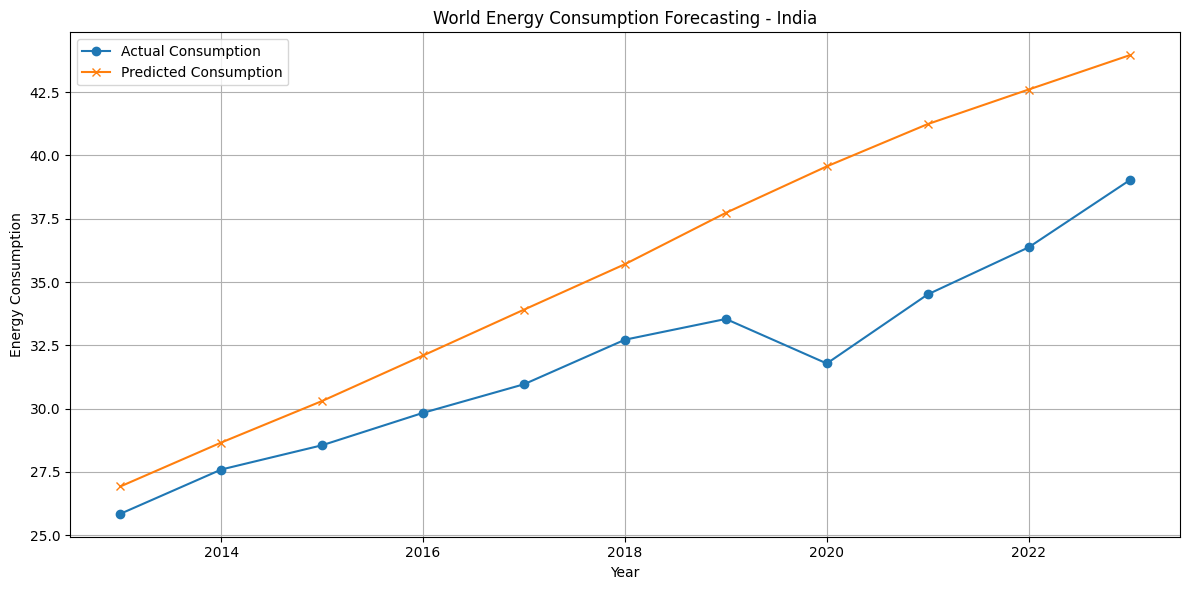

In [13]:

import matplotlib.pyplot as plt
import pandas as pd

# Create prediction results table
results = pd.DataFrame({
    "Year": years_test,
    "Actual Consumption": actual,
    "Predicted Consumption": predicted
})

print("Actual vs Predicted Energy Consumption:")
display(results)

# Plot graph
plt.figure(figsize=(12, 6))

plt.plot(
    years_test,
    actual,
    marker="o",
    label="Actual Consumption"
)

plt.plot(
    years_test,
    predicted,
    marker="x",
    label="Predicted Consumption"
)

plt.title("World Energy Consumption Forecasting - India")
plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
